# 02 — MLP on window-level features

Pipeline:
1. **Input**: 5 s windows (50% overlap) → 156 features each (`src/features.py`; run `python -m src.features` first).
2. **Model**: MLP 156 → 256 → 128 → 3 (BatchNorm, ReLU, dropout 0.3), trained on recording-level labels (`rec_label`).
3. **Training**: weighted cross-entropy (inverse class frequency), Adam, early stopping on validation loss.
4. **Patient prediction**: mean of window probabilities per recording → max over recordings of P(Present) and P(Unknown) → hierarchical rule with thresholds tuned on validation for the weighted accuracy.

Protocol: 5-fold CV on the development patients (folds 0–4). The test set (fold −1) is only used in the last section.

In [6]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.features import load_features
from src.metrics import CLASSES, report
from src.mlp import DEFAULT_CFG, cross_validate, patient_scores, predict_rule, tune_thresholds, predict_ensemble
pd.set_option('display.width', 140)

In [ ]:
df, feats = load_features(win=5, hop=2.5)
cfg = dict(DEFAULT_CFG)
print(len(df), 'windows,', len(feats), 'features')
cfg

24198 windows, 156 features


{'hidden': (256, 128),
 'dropout': 0.3,
 'lr': 0.001,
 'weight_decay': 0.0001,
 'batch_size': 256,
 'max_epochs': 100,
 'patience': 10,
 'weight_power': 1.0,
 'label_col': 'rec_label',
 'seed': 42}

## Cross-validation (one model per fold)

In [8]:
dev, oof, runs = cross_validate(df, feats, cfg)

fold 0: best epoch 0, val loss 0.930, window acc 0.497
fold 1: best epoch 0, val loss 0.878, window acc 0.519
fold 2: best epoch 2, val loss 0.979, window acc 0.522
fold 3: best epoch 2, val loss 0.855, window acc 0.578
fold 4: best epoch 0, val loss 0.901, window acc 0.496


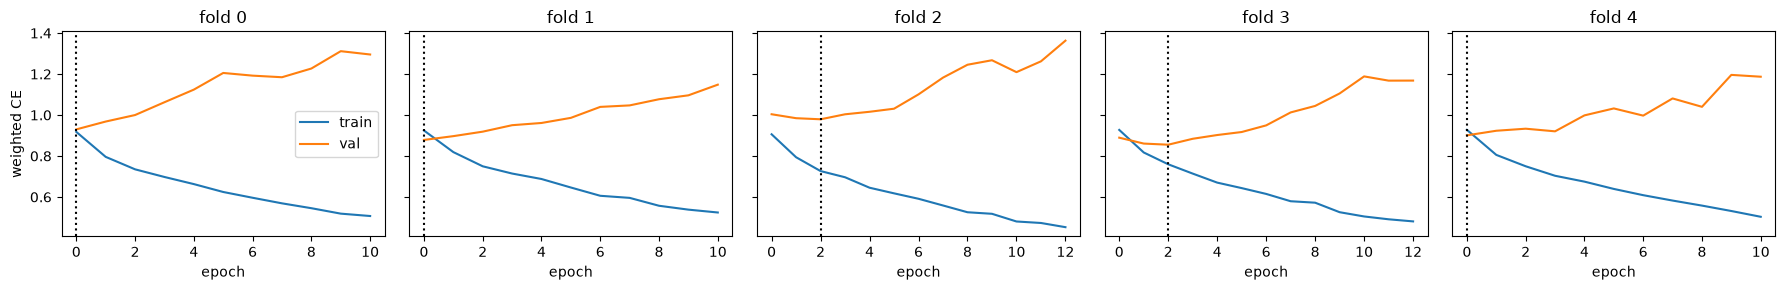

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3), sharey=True)
for r, ax in zip(runs, axes):
    h = r['history']
    ax.plot(h.epoch, h.train_loss, label='train'); ax.plot(h.epoch, h.val_loss, label='val')
    ax.axvline(h.val_loss.idxmin(), ls=':', c='k'); ax.set(title=f"fold {r['fold']}", xlabel='epoch')
axes[0].set_ylabel('weighted CE'); axes[0].legend(); plt.tight_layout()

## Patient-level evaluation

Thresholds are tuned **without looking at the fold being evaluated**: for each fold k, (t_present, t_unknown) are
chosen on the out-of-fold predictions of the other 4 folds, then applied to fold k. This gives an honest CV estimate.

In [10]:
pat = patient_scores(dev, oof)
pat['fold'] = dev.groupby('patient_id')['fold'].first()

rows, pred = [], pd.Series(index=pat.index, dtype=object)
for k in sorted(pat.fold.unique()):
    val, other = pat[pat.fold == k], pat[pat.fold != k]
    t, _ = tune_thresholds(other)
    pred[val.index] = predict_rule(val, *t)
    rows.append({'fold': k, 't_present': t[0], 't_unknown': t[1],
                 'WA (t=0.5)': report(val.murmur, predict_rule(val, .5, .5))['weighted_accuracy'],
                 'WA (tuned)': report(val.murmur, pred[val.index])['weighted_accuracy']})
cv = pd.DataFrame(rows).set_index('fold')
display(cv.round(3))
print('WA tuned: %.3f ± %.3f' % (cv['WA (tuned)'].mean(), cv['WA (tuned)'].std()))

,t_present,t_unknown,WA (t=0.5),WA (tuned)
fold,,,,
0,0.450,0.700,0.557,0.595
1,0.475,0.875,0.554,0.600
2,0.475,0.700,0.504,0.595
3,0.475,0.700,0.651,0.692
4,0.475,0.700,0.587,0.622


WA tuned: 0.621 ± 0.041


In [11]:
r = report(pat.murmur, pred)
print('pooled CV WA = %.3f' % r['weighted_accuracy'])
print('recall:', {c: round(v, 3) for c, v in r['recall'].items()})
pd.DataFrame(r['confusion'], index=[f'pred {c}' for c in CLASSES], columns=[f'true {c}' for c in CLASSES])

pooled CV WA = 0.621
recall: {'Present': np.float64(0.727), 'Unknown': np.float64(0.241), 'Absent': np.float64(0.595)}


,true Present,true Unknown,true Absent
pred Present,104,12,191
pred Unknown,8,13,34
pred Absent,31,29,331


Final thresholds for the test / hidden set: tuned on all out-of-fold predictions.

In [12]:
t_final, wa_oof = tune_thresholds(pat)
print('t_present = %.3f, t_unknown = %.3f (OOF WA %.3f, optimistic)' % (*t_final, wa_oof))

t_present = 0.475, t_unknown = 0.700 (OOF WA 0.634, optimistic)


## Test set — run only once, at the very end

Ensemble of the 5 fold models (average of window probabilities) + `t_final`. Nothing here may be used to change the model.

In [13]:
RUN_TEST = False
if RUN_TEST:
    test = df[df.fold == -1]
    pat_test = patient_scores(test, predict_ensemble(runs, test, feats))
    r = report(pat_test.murmur, predict_rule(pat_test, *t_final))
    print('TEST WA = %.3f' % r['weighted_accuracy'], {c: round(v, 3) for c, v in r['recall'].items()})
    display(pd.DataFrame(r['confusion'], index=[f'pred {c}' for c in CLASSES], columns=[f'true {c}' for c in CLASSES]))